# Sweep results
Reads `out/*/` (written by `run.py`). Re-run all cells after new runs finish.

In [26]:
import json, glob, os
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)

rows, hists = [], {}
for d in sorted(glob.glob("out/*/")):
    name = os.path.basename(d.rstrip("/"))
    if not (os.path.exists(d+"config.json") and os.path.exists(d+"results.json")):
        continue                                   # still running or failed
    cfg = json.load(open(d+"config.json")); res = json.load(open(d+"results.json"))
    if cfg["model"] == "baselines":                # {baseline: {pair: metrics}}
        for bname, per_pair in res.items():
            for pair, m in per_pair.items():
                rows.append({"run": bname, "model": "baseline", "overrides": "", "min": None, "pair": pair, **m})
    else:                                          # {ALL/pair: metrics}
        hists[name] = json.load(open(d+"history.json"))
        for pair, m in res.items():
            rows.append({"run": name, "model": cfg["model"], "overrides": " ".join(cfg["overrides"]),
                         "min": cfg["minutes"], "pair": pair, **m})
df = pd.DataFrame(rows)
print(len(df.run.unique()), "runs loaded")

7 runs loaded


## Pooled (ALL), sorted by switch PR-AUC

In [27]:
cols = ["model","overrides","switch_PR_AUC","dur_macro_F1","switch_P","switch_R","joint_acc","val_ce_sw","val_ce_dur","min"]
a = df[df.pair=="ALL"].set_index("run")[cols]
a["score"] = 0.5*(a.switch_PR_AUC + a.dur_macro_F1)    # same as trainer.select_score
a.sort_values("score", ascending=False)

,model,overrides,switch_PR_AUC,dur_macro_F1,switch_P,switch_R,joint_acc,val_ce_sw,val_ce_dur,min,score
run,,,,,,,,,,,
all_qw4b_300,qwen,"PAIR_SEL=""all"" MAX_CONV_PER_PAIR=300 QWEN_EPOC...",0.776,0.585,0.632,0.774,0.898,0.1771,0.8796,9.3,0.6805
all_xlmr_300,xlmr,"PAIR_SEL=""all"" MAX_CONV_PER_PAIR=300 QWEN_EPOC...",0.733,0.576,0.574,0.773,0.885,0.2109,0.9096,13.9,0.6545
all_qwen_300,qwen,"PAIR_SEL=""all"" MAX_CONV_PER_PAIR=300 QWEN_EPOC...",0.712,0.533,0.604,0.718,0.890,0.2086,0.9248,3.5,0.6225


## Per pair

In [28]:
for metric in ["switch_PR_AUC", "dur_macro_F1", "joint_acc"]:
    print("\n==", metric, "==")
    display(df[df.pair!="ALL"].pivot(index="run", columns="pair", values=metric))


== switch_PR_AUC ==


pair,ar-en,de-en,es-en,fr-en,hi-en,it-en,ja-en,ko-en,ru-en,vi-en,yue-en,zh-en
run,,,,,,,,,,,,
B0 always-switch,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
B0 never-switch,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
B1 lookup,0.530,0.411,0.397,0.377,0.427,0.432,0.358,0.643,0.450,0.405,0.238,0.353
B2 char-ngram LR,0.493,0.505,0.405,0.469,0.597,0.510,0.637,0.846,0.476,0.476,0.242,0.314
all_qw4b_300,0.830,0.786,0.680,0.707,0.835,0.776,0.855,0.944,0.757,0.679,0.565,0.820
all_qwen_300,0.767,0.737,0.652,0.686,0.748,0.715,0.770,0.899,0.695,0.644,0.472,0.732
all_xlmr_300,0.785,0.724,0.649,0.646,0.817,0.734,0.816,0.916,0.751,0.667,0.493,0.759



== dur_macro_F1 ==


pair,ar-en,de-en,es-en,fr-en,hi-en,it-en,ja-en,ko-en,ru-en,vi-en,yue-en,zh-en
run,,,,,,,,,,,,
B0 always-switch,0.162,0.161,0.163,0.207,0.201,0.246,0.189,0.189,0.159,0.245,0.203,0.224
B0 never-switch,0.162,0.161,0.163,0.207,0.201,0.246,0.189,0.189,0.159,0.245,0.203,0.224
B1 lookup,0.258,0.213,0.252,0.343,0.201,0.361,0.189,0.311,0.331,0.363,0.273,0.224
B2 char-ngram LR,0.443,0.401,0.364,0.431,0.410,0.492,0.500,0.458,0.511,0.496,0.429,0.456
all_qw4b_300,0.580,0.529,0.504,0.599,0.588,0.583,0.604,0.507,0.602,0.453,0.600,0.462
all_qwen_300,0.555,0.505,0.461,0.580,0.502,0.508,0.561,0.508,0.586,0.442,0.449,0.466
all_xlmr_300,0.593,0.480,0.522,0.567,0.576,0.584,0.560,0.543,0.639,0.485,0.573,0.474



== joint_acc ==


pair,ar-en,de-en,es-en,fr-en,hi-en,it-en,ja-en,ko-en,ru-en,vi-en,yue-en,zh-en
run,,,,,,,,,,,,
B0 always-switch,0.041,0.037,0.038,0.048,0.032,0.056,0.028,0.069,0.035,0.076,0.042,0.038
B0 never-switch,0.872,0.883,0.883,0.892,0.927,0.904,0.929,0.824,0.889,0.870,0.903,0.925
B1 lookup,0.725,0.619,0.567,0.622,0.692,0.655,0.888,0.767,0.706,0.819,0.816,0.855
B2 char-ngram LR,0.760,0.775,0.751,0.784,0.839,0.787,0.866,0.840,0.786,0.763,0.768,0.818
all_qw4b_300,0.882,0.888,0.862,0.888,0.937,0.897,0.941,0.885,0.896,0.852,0.878,0.928
all_qwen_300,0.860,0.880,0.864,0.889,0.925,0.894,0.931,0.881,0.875,0.854,0.865,0.914
all_xlmr_300,0.865,0.870,0.848,0.871,0.932,0.887,0.923,0.881,0.886,0.851,0.861,0.913


## Training curves (val metrics per epoch, ALL)
Note `val_loss` is not comparable between XLM-R and Qwen3.

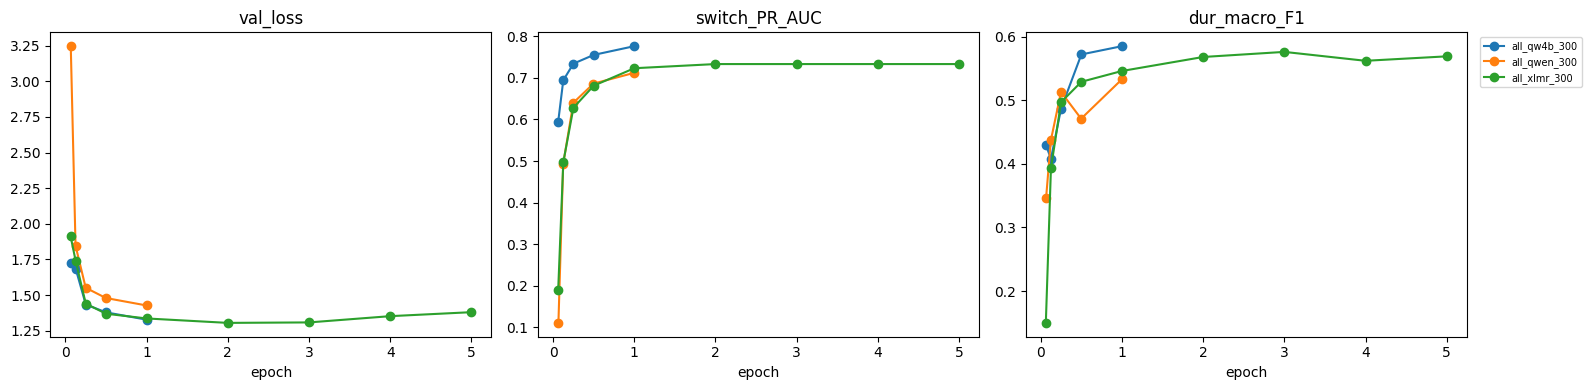

In [29]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
def unpack(h):
    # New: {"step","epoch","res"}; Old: one res dict/epoch
    if h and "res" in h[0]:
        return [e["epoch"] for e in h], [e["res"] for e in h]
    return list(range(1, len(h) + 1)), h

for name, h in hists.items():
    ep, rs = unpack(h)
    ax[0].plot(ep, [r["ALL"]["val_loss"] for r in rs], marker="o", label=name)
    ax[1].plot(ep, [r["ALL"]["switch_PR_AUC"] for r in rs], marker="o", label=name)
    ax[2].plot(ep, [r["ALL"]["dur_macro_F1"] for r in rs], marker="o", label=name)
for x, t in zip(ax, ["val_loss", "switch_PR_AUC", "dur_macro_F1"]):
    x.set_title(t); x.set_xlabel("epoch")
ax[2].legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()